In [1]:
import sys
import os
from collections import defaultdict
import pandas as pd
import scanpy as sc
import numpy as np
import numpy as np
import matplotlib.pyplot as plt
from glmpca import glmpca
from itertools import combinations
import torch

import sys
from importlib import reload

import gaston
from gaston import neural_net,cluster_plotting, dp_related, segmented_fit, restrict_spots, model_selection
from gaston import binning_and_plotting, isodepth_scaling, run_slurm_scripts, parse_adata
from gaston import spatial_gene_classification, plot_cell_types, filter_genes, process_NN_output

import seaborn as sns
import math
from numpy.random import default_rng

/Users/phillipnicol/miniforge3/envs/gaston-morphogam/lib/python3.11/site-packages/dask/dataframe/_pyarrow_compat.py:17: FutureWarning: Minimal version of pyarrow will soon be increased to 14.0.1. You are using 13.0.0. Please consider upgrading.
  warnings.warn(
/Users/phillipnicol/miniforge3/envs/gaston-morphogam/lib/python3.11/site-packages/xarray_schema/__init__.py:1: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import DistributionNotFound, get_distribution


In [2]:
# Load gene labels
gene_labels = pd.read_csv("../../data/mucosa_retained_rownames.csv")
gene_labels = gene_labels['x'].values
np.save("../data/gene_labels.npy", gene_labels)

In [3]:
# gaston_model, A, S= process_NN_output.process_files('colorectal_tumor_tutorial_outputs') # model trained above
gaston_model, A, S= process_NN_output.process_files('colorectal_tumor_tutorial_outputs') # MATCH PAPER FIGURES

# May need to re-load counts_mat, coords_mat, and gene_labels
counts_mat=np.load('../data/counts_mat.npy',allow_pickle=True) # download from google drive folder
coords_mat=np.load('../data/coords_mat.npy',allow_pickle=True)
gene_labels=np.load('../data/gene_labels.npy',allow_pickle=True)


best model: colorectal_tumor_tutorial_outputs/rep27


Kneedle number of domains: 4


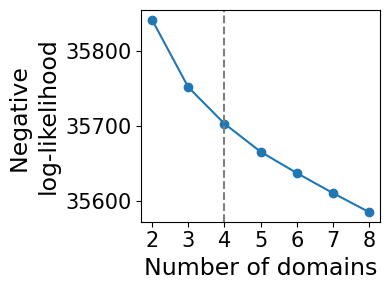

In [4]:
model_selection.plot_ll_curve(gaston_model, A, S, max_domain_num=8, start_from=2,num_buckets=100)

In [5]:
num_layers=4 # From the above plot
gaston_isodepth, gaston_labels=dp_related.get_isodepth_labels(gaston_model,A,S,num_layers)

# DATASET-SPECIFIC: so domains are ordered with tumor being last
gaston_isodepth= np.max(gaston_isodepth) -1 * gaston_isodepth
gaston_labels=(num_layers-1)-gaston_labels

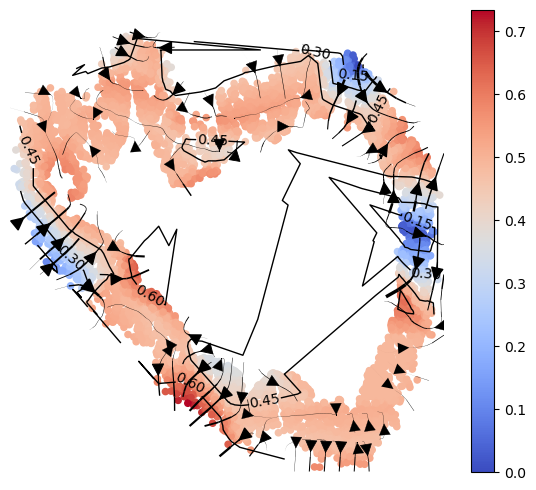

In [6]:
show_streamlines=True
rotate = np.radians(-90) # rotate coordinates by -90
arrowsize=2

cluster_plotting.plot_isodepth(gaston_isodepth, S, gaston_model, figsize=(7,6), streamlines=show_streamlines, 
                               rotate=rotate,arrowsize=arrowsize, 
                               neg_gradient=True) # since we did isodepth -> -1*isodepth above, we also need to do gradient -> -1*gradient

In [9]:
reload(segmented_fit)
# compute piecewise linear fit for restricted spots
pw_fit_dict=segmented_fit.pw_linear_fit(counts_mat.T, gaston_labels, gaston_isodepth,
                                        None, [],  umi_threshold=10, isodepth_mult_factor=0.01,)
# for plotting
binning_output=binning_and_plotting.bin_data(counts_mat.T, gaston_labels, gaston_isodepth, 
                         None, gene_labels, num_bins=15, umi_threshold=10)

Poisson regression for ALL cell types


  0%|          | 0/661 [00:00<?, ?it/s]/Users/phillipnicol/miniforge3/envs/gaston-morphogam/lib/python3.11/site-packages/sklearn/_loss/link.py:173: RuntimeWarning: divide by zero encountered in log
  return np.log(y_pred, out=out)
/Users/phillipnicol/miniforge3/envs/gaston-morphogam/lib/python3.11/site-packages/sklearn/_loss/link.py:173: RuntimeWarning: divide by zero encountered in log
  return np.log(y_pred, out=out)
/Users/phillipnicol/miniforge3/envs/gaston-morphogam/lib/python3.11/site-packages/gaston/segmented_fit.py:138: RuntimeWarning: divide by zero encountered in log
  return np.sum(y * np.log(lam) - lam)
/Users/phillipnicol/miniforge3/envs/gaston-morphogam/lib/python3.11/site-packages/gaston/segmented_fit.py:138: RuntimeWarning: invalid value encountered in multiply
  return np.sum(y * np.log(lam) - lam)
  3%|▎         | 18/661 [00:00<00:07, 81.72it/s]/Users/phillipnicol/miniforge3/envs/gaston-morphogam/lib/python3.11/site-packages/gaston/segmented_fit.py:138: RuntimeWarning

In [10]:
slope_mat, intercept_mat, discont_mat, pv_mat = pw_fit_dict["all_cell_types"]

# These are the genes retained by GASTON after UMI filtering.
gene_labels_idx = binning_output["gene_labels_idx"]

abs_slope_mat = np.abs(slope_mat)

# For each gene, find the layer/domain where its absolute ISODEPTH slope is largest.
best_layer = np.argmax(abs_slope_mat, axis=1)

gaston_gene_rankings = pd.DataFrame({
    "gene": gene_labels_idx,
    "best_layer": best_layer,
    "slope": slope_mat[np.arange(slope_mat.shape[0]), best_layer],
    "abs_slope": abs_slope_mat[np.arange(slope_mat.shape[0]), best_layer],
    "p_value": pv_mat[np.arange(pv_mat.shape[0]), best_layer],
    "min_p_value": np.min(pv_mat, axis=1),
})

gaston_gene_rankings = (
    gaston_gene_rankings
    .sort_values("min_p_value", ascending=True)
    .reset_index(drop=True)
)

gaston_gene_rankings["isodepth_rank"] = np.arange(1, len(gaston_gene_rankings) + 1)

display(gaston_gene_rankings.head(50))

#Save gaston_gene_rankings to data
gaston_gene_rankings.to_csv("../data/gaston_gene_rankings.csv", index=False)

,gene,best_layer,slope,abs_slope,p_value,min_p_value,isodepth_rank
0,Erbb3,1,10.000992,10.000992,4.756498e-30,4.756498e-30,1
1,Dhx58,2,120.415167,120.415167,2.187437e-27,2.187437e-27,2
2,Scnn1a,1,7.580631,7.580631,6.741364e-13,6.741364e-13,3
3,Nlrp6,2,35.521535,35.521535,4.457413e-12,4.457413e-12,4
4,Ptprr,1,20.043029,20.043029,1.598419e-10,1.598419e-10,5
5,Ddx58,2,113.420221,113.420221,1.433123e-07,1.685012e-10,6
6,Ano1,0,0.622176,0.622176,4.303021e-09,4.303021e-09,7
7,Ephb4,2,-44.122364,44.122364,2.831250e-06,7.628803e-08,8
8,Vegfa,2,-63.626372,63.626372,9.339099e-08,9.339099e-08,9
9,Efnb2,1,12.681714,12.681714,2.163532e-07,2.163532e-07,10


In [11]:
counts_mat.shape

(694, 7209)

In [12]:
pw_fit_dict

{'all_cell_types': (array([[  0.        , -47.04609244,   0.        ,   0.        ],
         [-13.55363403,   0.        ,   0.        ,   0.        ],
         [-10.77290907,   0.        ,   0.        ,   0.        ],
         ...,
         [  0.        ,   0.        ,   0.        ,   0.        ],
         [  0.        ,   0.        ,   0.        ,   0.        ],
         [  0.        ,   4.97626616,  16.81395051,  -2.17249508]]),
  array([[ -9.29876594,  13.41002341,  -8.85366543,  -9.30327761],
         [ -8.35309276, -10.37456482, -11.56171563,   0.        ],
         [ -8.03184352, -10.6622469 , -10.46310334, -10.33289703],
         ...,
         [-10.18606914,  -9.74595616, -10.17542127,  -9.8628934 ],
         [ -7.94232455,  -8.21989986,  -8.1944198 ,  -8.38698688],
         [ -4.65607332,  -7.12397018, -13.10233258,  -3.47572113]]),
  array([[ 1.44983795,  1.09524525, -0.44961218],
         [ 4.101344  , -1.18715081, 11.56171563],
         [ 2.23622801,  0.19914356,  0.1302063

In [13]:
gene_name = "Ddx58"
binning_and_plotting.plot_gene_raw(gene_name, gene_labels, counts_mat, S, vmin=8.5, figsize=(6,4))
plt.title(f'{gene_name} Raw Expression')
binning_and_plotting.plot_gene_function(gene_name, S, pw_fit_dict, gaston_labels, gaston_isodepth, binning_output, figsize=(6,4))
plt.title(f'{gene_name} GASTON Function')
plt.show()

ValueError: 'c' argument has 694 elements, which is inconsistent with 'x' and 'y' with size 7209.

In [58]:
offset=10**6
binning_and_plotting.plot_gene_pwlinear('Ephb4', pw_fit_dict, gaston_labels, gaston_isodepth, 
                                        binning_output, cell_type_list=None, pt_size=70, 
                                        linear_fit=True, ticksize=15, figsize=(7,3), offset=offset, lw=2,
                                       domain_boundary_plotting=True)

IndexError: list index out of range

In [59]:
#Row names of count_mat
gene_labels[300:500]

array(['Il23a', 'Il27ra', 'Il31ra', 'Il34', 'Il3ra', 'Il4ra', 'Il5ra',
       'Il6ra', 'Il6st', 'Il7', 'Insr', 'Insrr', 'Isl1', 'Itga2', 'Itgae',
       'Itgam', 'Itgb2', 'Itpr1', 'Itpr2', 'Itpr3', 'Jag1', 'Jag2',
       'Jaml', 'Kif16b', 'Kif5a', 'Kiss1r', 'Kit', 'Kitl', 'Lefty1',
       'Lefty2', 'Lgr4', 'Lgr6', 'Lif', 'Lifr', 'Lmtk2', 'Lmtk3', 'Lpar1',
       'Lpar2', 'Lpar5', 'Lpar6', 'Lrp5', 'Lrp6', 'Lrrk2', 'Ltb',
       'Ltb4r1', 'Ltb4r2', 'Ltk', 'Ly75', 'Lyve1', 'Maged2', 'Marcksl1',
       'Mc1r', 'Mc2r', 'Mc3r', 'Mc4r', 'Mc5r', 'Mcm2', 'Mertk', 'Met',
       'Mfap5', 'Mitf', 'Mki67', 'Mrc1', 'Mrgpra1', 'Mrgpre', 'Mrgprf',
       'Mst1r', 'Muc1', 'Muc4', 'Myh10', 'Mzb1', 'Naip1', 'Naip2',
       'Naip5', 'Naip6', 'Neurog3', 'Nlrc4', 'Nlrc5', 'Nlrp10', 'Nlrp12',
       'Nlrp1b', 'Nlrp2', 'Nlrp6', 'Nlrp9b', 'Nlrx1', 'Nmbr', 'Nmur2',
       'Nod1', 'Nod2', 'Nodal', 'Nos2', 'Notch1', 'Notch2', 'Notch4',
       'Npffr1', 'Npy1r', 'Npy2r', 'Nr1d1', 'Nr1d2', 'Nr1h2', 'Nr1h3',
       